To run this, press "*Run*" and press "*Run All Cells*" on your local Mac machine!
<div class="align-center">

[](https://asystem-ai.io/docs/areno/getting-started/installation.html) [](https://asystem-ai.io/docs/areno/getting-started/installation.html) ⭐ <i>Star us on <a href="https://github.com/inclusionAI/AReno">Github</a> </i> ⭐

</div>

To install AReno on your local device, follow [our guide](https://asystem-ai.io/docs/areno/getting-started/installation.html). This notebook is licensed under [Apache-2.0](https://www.apache.org/licenses/LICENSE-2.0).

You will learn how to do [data setup](#data), how to [train](#train), how to [run the model](#inference)


<a id="setup"></a>

## 1. 🛠️ Installation


Currently, AReno can only be installed from source. To install it on your Mac, run the commands below. The minimum system requirements are **16GB of unified memory** and about **25GB of free disk space**.

In [ ]:
%%bash
git clone https://github.com/inclusionAI/AReno.git AReno
pip install -e AReno

<a id="data"></a>

## 2. 📦 Model and Data


We'll be using the [original BF16 Ling-3.0-tiny model](https://huggingface.co/inclusionAI/Ling-3.0-tiny). The goal is to read orders, balances, and promotion rules, then return a payment plan and recommend a cheaper option.

You can access the dataset [here](https://huggingface.co/datasets/AsystemAReno/Ling-Ting-SFT-Augment): **1,115 training examples** (`train.jsonl`), **100 validation examples** (`valid.jsonl`), and **500 test cases** (`eval500.jsonl`).

Let's take a look at an example. We'll compare two payment options for a **CNY 0.99** order.

**🧾 Input scenario**

- Preferred wallet balance: **CNY 0.21**. SPDB card balance: **CNY 2.97**.
- General promotion: **CNY 0.02** off orders of at least **CNY 0.24**. SPDB promotion: an additional **CNY 0.19** off orders of at least **CNY 0.33**; the discounts can stack.

**Input excerpt**

```jsonc
{
  "order": {"order_amount": 99}, // Amounts are in fen: 99 fen = CNY 0.99
  "selected_channel_id": "DIGITAL_RMB_WALLET_8752",
  "available_channels": [
    {"channel_id": "DIGITAL_RMB_WALLET_8752", "balance": 21},
    {"channel_id": "BANK_SPDB_CARD_2565", "balance": 297}
  ],
  "promotions": [
    // A general 2-fen discount; the SPDB card adds a stackable 19-fen discount
    {"applicable_channel_id": null, "threshold": 24, "discount_amount": 2},
    {"applicable_channel_id": "BANK_SPDB_CARD_2565", "threshold": 33, "discount_amount": 19}
  ]
}
```

**Option 1: Split the payment using the preferred wallet**

- We apply the **CNY 0.02** discount, leaving **CNY 0.97** to pay.
- We use **CNY 0.21** from the wallet and **CNY 0.76** from the SPDB card.

We can see this plan in the reference answer's `cashier_receipt`:

```jsonc
{
  "status": "SUCCESS",
  "cashier_receipt": {
    "primary_deduct_amount": 21,   // Preferred wallet
    "secondary_deduct_amount": 76, // SPDB card covers the rest
    "total_discount_amount": 2,
    "payable_amount": 97
  }
}
```

**Option 2: Pay with the SPDB card alone (recommended)**

- We stack the discounts: **CNY 0.02 + 0.19 = 0.21**.
- We pay **CNY 0.78** with the card, saving **CNY 0.19** compared with the split payment.

We also get the cheaper option in the same answer's `recommended_option`:

```jsonc
{
  "recommended_option": {
    "recommended_channel_id": "BANK_SPDB_CARD_2565",
    "payable_amount": 78,         // Pay with the SPDB card alone
    "total_discount_amount": 21
  }
}
```


<a id="train"></a>

## 3. 🚀 Train the model


Now let's train our model. We do **500 steps** with **on-the-fly 4-bit quantization** and add LoRA adapters to the **Attention / MLP modules across all 24 layers**.


In [ ]:
%%bash
train_args=(
  --algo sft --model-hub hf
  --ckpt inclusionAI/Ling-3.0-tiny
  --dataset-path AsystemAReno/Ling-Ting-SFT-Augment::train
  --dataset-loader-fn AReno/examples/sft/ling_payment/dataset_loader.py
  --validation-dataset-path AsystemAReno/Ling-Ting-SFT-Augment::validation
  # Token-weighted validation before scheduled updates.
  --eval-batches 25 --eval-before-step
  --shuffle --seed 0
  --q4  # Quantize the frozen base model to 4-bit at load time.
  --lora-rank 4 --lora-alpha 32 --lora-dropout 0.05
  # Attention/MLP adapters across all 24 layers; base weights stay frozen.
  --lora-target-modules q_proj,k_proj,v_proj,f_proj,o_proj,g_proj,b_proj,q_a_proj,q_b_proj,kv_a_proj_with_mqa,dense,gate_proj,up_proj,down_proj
  # Single-example microbatches; activation checkpointing is on by default.
  --batch-size 1 --mini-bs 1 --score-micro-bs 1
  --epochs 1 --max-steps 500
  --max-new-tokens 1024
  --lr 2e-5 --min-lr 2e-5 --lr-decay-style constant --weight-decay 0
  --no-adam-bias-correction  # Skip correction for zero-initialized Adam moment estimates.
  --no-grad-clip  
  --no-mlx-compile-train-step  # Skip mx.compile for the loss/gradient function.
  --save-path runs/q4-cli/adapters  # Save adapters every 100 steps (default).
  --metrics-log-dir runs/q4-cli/events
)
areno train "${train_args[@]}"


To save the LoRA adapters locally, we use `--save-path`. The final adapter is saved to `runs/q4-cli/adapters/step_000500/`.

We can also view the training metrics in the Dashboard:


In [ ]:
%%bash
areno dashboard --start


We can see the loss, step times, and logs in the [AReno Dashboard](http://127.0.0.1:8765) under **Jobs**.

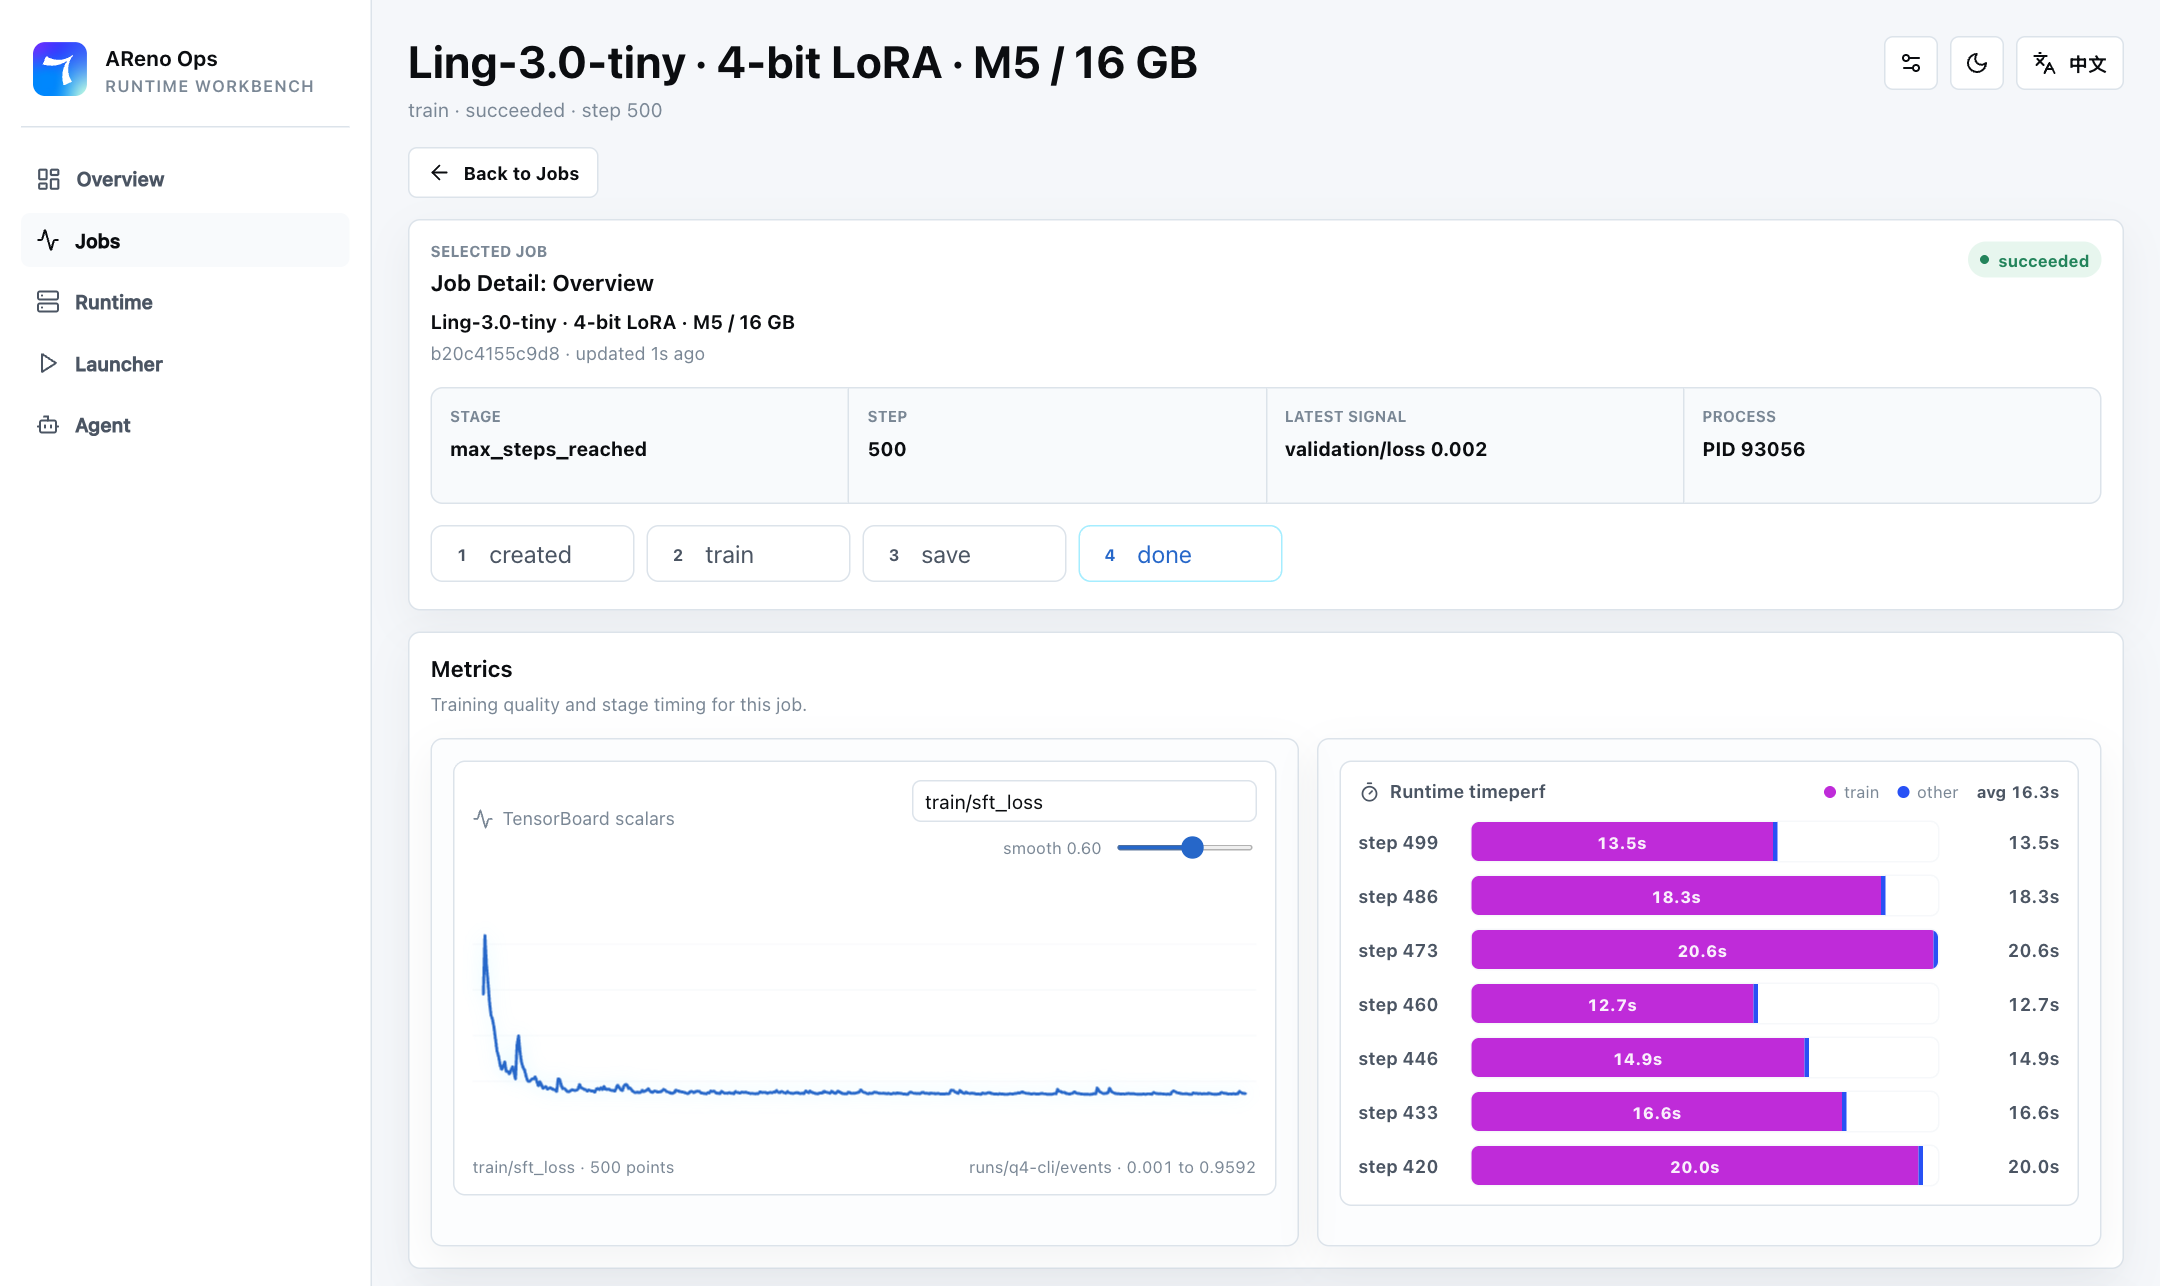

*Figure 1: Our 500-step training run in the Dashboard.*

We also support [DPO / GRPO / GSPO / PPO](https://asystem-ai.io/docs/areno/cli/training.html), [Agentic RL](https://asystem-ai.io/docs/areno/getting-started/welcome.html#agentic-rollout), and [8-bit AdamW](https://asystem-ai.io/docs/areno/concepts/adamw-8bit.html).


<a id="inference"></a>

## 4. 🧪 Inference


Let's run the model! Use `areno serve` to load previous saved LoRA adapters and start an **OpenAI-compatible server**:

In [ ]:
%%bash --bg
areno serve \
  --backend mlx \
  --model-hub hf \
  --model-path inclusionAI/Ling-3.0-tiny \
  --lora-adapter-path runs/q4-cli/adapters/step_000500 \
  --host 127.0.0.1 --port 8000 \
  --max-running-prompts 2 --default-max-tokens 4096

Let's evaluate the model on **500 payment cases**! We send only the rules and questions, and save the responses to `eval_results.jsonl`.

We use **exact-match accuracy** on the final JSON: values and array order must match the reference; key order can differ. Responses that cannot be parsed as JSON count as incorrect.


In [ ]:
import json
from pathlib import Path
from huggingface_hub import hf_hub_download
from openai import OpenAI

client = OpenAI(base_url="http://127.0.0.1:8000/v1", api_key="local", timeout=600)
model = client.models.list().data[0].id
eval_path = Path(hf_hub_download(
    repo_id="AsystemAReno/Ling-Ting-SFT-Augment",
    filename="eval500.jsonl",
    repo_type="dataset",
))
cases = [json.loads(line) for line in eval_path.read_text(encoding="utf-8").splitlines() if line.strip()]
results = []

for i, case in enumerate(cases, 1):
    response = client.chat.completions.create(
        model=model,
        # Send only the rules and question, excluding the reference assistant answer
        messages=[m for m in case["messages"] if m["role"] != "assistant"],
        temperature=0.1,
        max_tokens=4096,
    )
    answer = response.choices[0].message.content or ""
    try:
        prediction = json.loads(answer.rsplit("</think>", 1)[-1].strip())
        correct = prediction == case["ground_truth"]
    except json.JSONDecodeError:
        correct = False
    results.append({"case_id": case["case_id"], "correct": correct, "output": answer})
    print(f"Completed {i}/{len(cases)}", end="\r")

Path("eval_results.jsonl").write_text(
    "\n".join(json.dumps(row, ensure_ascii=False) for row in results) + "\n",
    encoding="utf-8",
)
correct = sum(row["correct"] for row in results)
print(f"\nTest accuracy: {correct}/{len(cases)} = {correct / len(cases):.2%}")

<a id="results"></a>

And we're done! Our **500-step** run on a **MacBook Air (M5) with 16GB of unified memory** trained **74,947,584 LoRA parameters** in **3 hours, 15 minutes, and 55 seconds**, with an MLX allocator peak of about **10.03GB**.

Our fine-tuned model gets **322/500** correct, or **64.4%** exact-match accuracy. This is **64.4 percentage points** above the existing **0%** baseline.

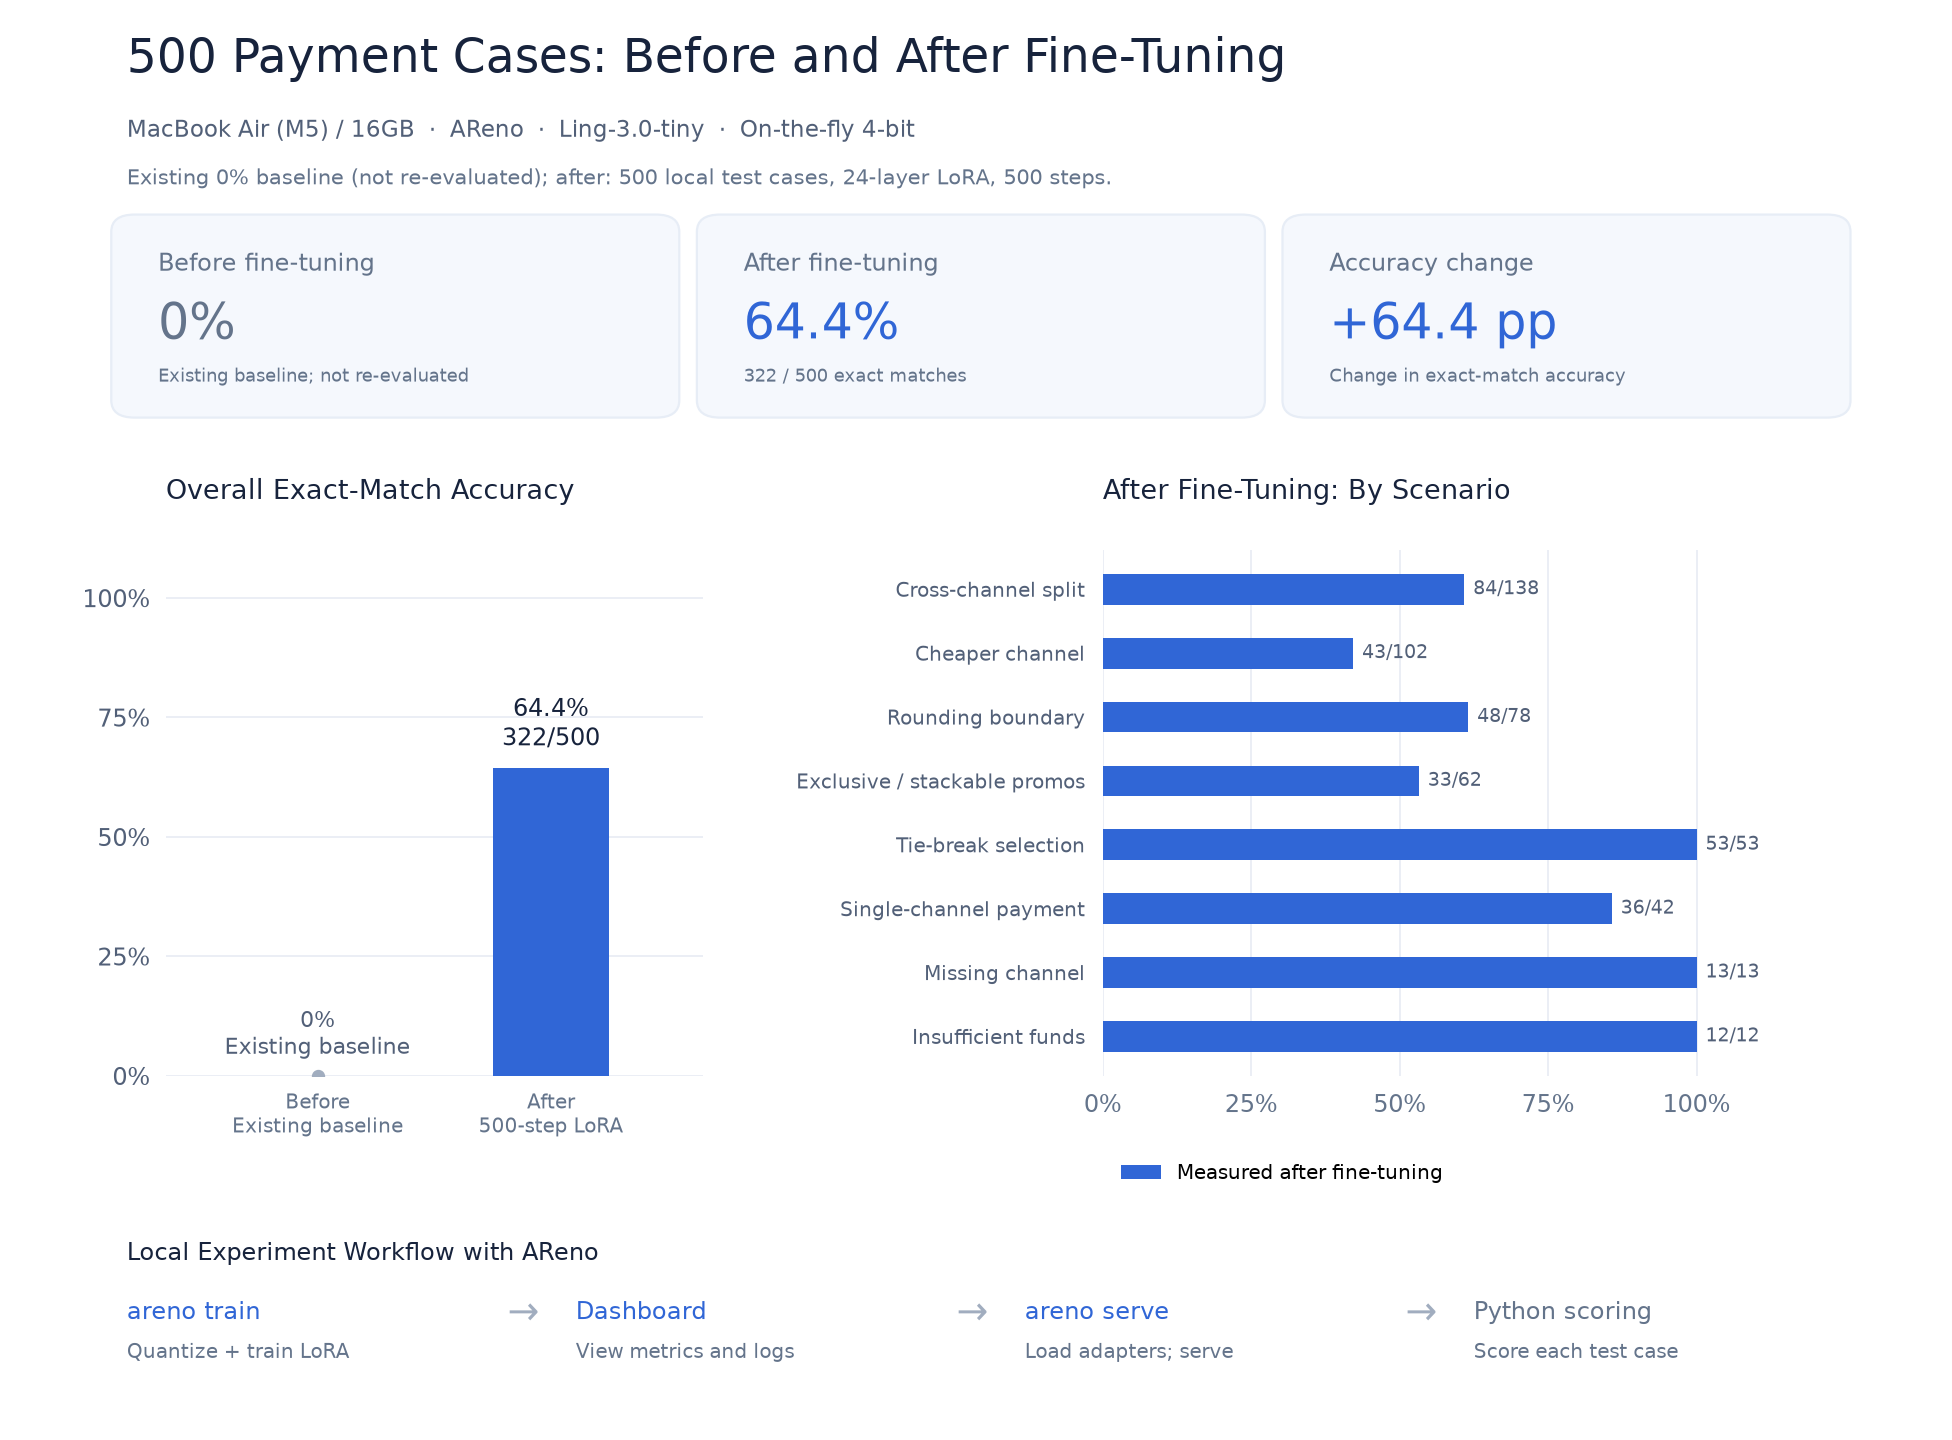

*Figure 2: Overall accuracy on the left and measured post-training accuracy by scenario on the right. Counts show correct answers / total cases in each scenario. Scenarios follow the test set's original labels. The pre-training result uses an existing baseline and was not re-evaluated in this run.*
